# Expectation-Maximisation and Gaussian Mixture Clustering

`05_clustering` covers hard clustering with k-means. This notebook adds the probabilistic view:

- a Gaussian mixture model (GMM) represents each cluster as a Gaussian component;
- the EM algorithm alternates between soft assignments and parameter updates;
- the result is a **soft** clustering, where each point has a responsibility for every component;
- BIC can help choose the number of components.

We implement EM for a two-dimensional GMM from scratch, compare it with scikit-learn, and contrast
it with k-means.

## Learning objectives

By the end of this notebook you can:

- write the E-step and M-step for a Gaussian mixture;
- implement EM with numerical stability safeguards;
- interpret responsibilities as soft cluster memberships;
- compare GMM and k-means on elongated clusters;
- use BIC to select the number of components.

## 1. The Gaussian mixture model

A GMM assumes that the data come from a mixture of $K$ Gaussian distributions:

$$
p(x) = \sum_{k=1}^{K} \pi_k\,\mathcal{N}(x\mid\mu_k,\Sigma_k),
\qquad
\sum_{k=1}^{K}\pi_k = 1.
$$

- $\pi_k$ is the mixing weight of component $k$;
- $\mu_k$ is its mean;
- $\Sigma_k$ is its covariance matrix.

For each point $x_i$, introduce a latent component label $z_i\in\{1,\dots,K\}$. The model says that
$x_i$ was generated by first choosing a component and then drawing from that Gaussian.

### The EM idea

EM maximises the observed-data log-likelihood

$$
\ell(\theta) = \sum_{i=1}^{n}\log\left(\sum_{k=1}^{K}\pi_k\mathcal{N}(x_i\mid\mu_k,\Sigma_k)\right).
$$

Direct optimisation is awkward because of the log of a sum. EM introduces responsibilities

$$
r_{ik} = P(z_i=k\mid x_i,\theta)
= \frac{\pi_k\mathcal{N}(x_i\mid\mu_k,\Sigma_k)}
{\sum_{j=1}^{K}\pi_j\mathcal{N}(x_i\mid\mu_j,\Sigma_j)}.
$$

Then it alternates:

- **E-step:** compute responsibilities with the current parameters;
- **M-step:** update weights, means, and covariances using the responsibilities as soft counts.

Each iteration increases the observed-data log-likelihood (or leaves it unchanged), up to numerical
error.

## 2. Numerical stability

Probabilities can underflow when points are far from a component. We therefore work with
log-densities and use the log-sum-exp trick:

$$
\log r_{ik} = \log\pi_k + \log\mathcal{N}(x_i\mid\mu_k,\Sigma_k) - \operatorname{logsumexp}_j(\cdots).
$$

The multivariate Gaussian log-density is

$$
\log\mathcal{N}(x\mid\mu,\Sigma)
= -\frac{1}{2}\left(d\log(2\pi)+\log\det\Sigma+(x-\mu)^\top\Sigma^{-1}(x-\mu)\right).
$$

A small ridge term is added to each covariance update to avoid singular matrices.

In [1]:
import os
import warnings

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
warnings.filterwarnings("ignore", message="A NumPy version")
warnings.filterwarnings("ignore", message="Could not find the number of physical cores")
warnings.filterwarnings("ignore", category=UserWarning, module="joblib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.special import logsumexp

from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## 3. Generate three elongated Gaussian clusters

The base clusters are isotropic, then a linear transformation stretches and rotates them. This is
where a full-covariance GMM has an advantage over k-means, which implicitly prefers round clusters.

In [2]:
X_isotropic, y_true = make_blobs(
    n_samples=450,
    centers=3,
    cluster_std=0.8,
    random_state=3,
)

transformation = np.array([[0.6, -0.6], [-0.4, 0.85]])
X = X_isotropic @ transformation.T
true_means = np.vstack([X[y_true == k].mean(axis=0) for k in range(3)])

permutation = rng.permutation(len(X))
X = X[permutation]
y_true = y_true[permutation]

print("Data shape:", X.shape)
print("True component counts:", np.bincount(y_true))

Data shape: (450, 2)
True component counts: [150 150 150]


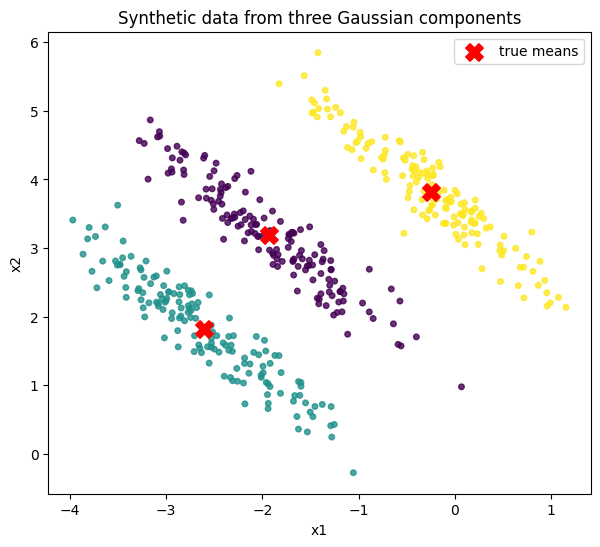

In [3]:
plt.figure(figsize=(7, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=y_true, cmap="viridis", s=16, alpha=0.8)
plt.scatter(true_means[:, 0], true_means[:, 1], c="red", marker="X", s=160, label="true means")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Synthetic data from three Gaussian components")
plt.legend()
plt.show()

## 4. Implement EM from scratch

In [4]:
def log_gaussian_pdf(X, mean, covariance):
    d = X.shape[1]
    sign, log_det = np.linalg.slogdet(covariance)
    if sign <= 0:
        return np.full(X.shape[0], -np.inf)
    diff = X - mean
    solved = np.linalg.solve(covariance, diff.T).T
    mahalanobis = np.sum(diff * solved, axis=1)
    return -0.5 * (d * np.log(2 * np.pi) + log_det + mahalanobis)


def e_step(X, weights, means, covariances):
    K = len(weights)
    log_probabilities = np.column_stack(
        [
            np.log(weights[k]) + log_gaussian_pdf(X, means[k], covariances[k])
            for k in range(K)
        ]
    )
    log_normalizer = logsumexp(log_probabilities, axis=1, keepdims=True)
    responsibilities = np.exp(log_probabilities - log_normalizer)
    log_likelihood = log_normalizer.sum()
    return responsibilities, log_likelihood


def m_step(X, responsibilities, reg=1e-6):
    n, d = X.shape
    K = responsibilities.shape[1]
    counts = np.maximum(responsibilities.sum(axis=0), 1e-10)
    weights = counts / counts.sum()

    means = np.zeros((K, d))
    covariances = np.zeros((K, d, d))

    for k in range(K):
        means[k] = (responsibilities[:, k, None] * X).sum(axis=0) / counts[k]
        diff = X - means[k]
        covariances[k] = (
            (responsibilities[:, k, None] * diff).T @ diff / counts[k]
            + reg * np.eye(d)
        )

    return weights, means, covariances


def initialize_parameters(X, K, local_rng):
    n, d = X.shape
    indices = local_rng.choice(n, size=K, replace=False)
    means = X[indices].copy()
    base_covariance = np.cov(X.T) + 1e-3 * np.eye(d)
    covariances = np.array([base_covariance.copy() for _ in range(K)])
    weights = np.ones(K) / K
    return weights, means, covariances

In [5]:
def fit_gmm_em(X, K, max_iter=100, tol=1e-6, reg=1e-6, n_init=5, seed=RANDOM_STATE):
    local_rng = np.random.default_rng(seed)
    best_result = None

    for run in range(n_init):
        weights, means, covariances = initialize_parameters(X, K, local_rng)
        log_likelihood_history = []

        for iteration in range(max_iter):
            responsibilities, log_likelihood = e_step(X, weights, means, covariances)
            log_likelihood_history.append(log_likelihood)

            new_weights, new_means, new_covariances = m_step(X, responsibilities, reg=reg)
            weights, means, covariances = new_weights, new_means, new_covariances

            if len(log_likelihood_history) >= 2:
                improvement = log_likelihood_history[-1] - log_likelihood_history[-2]
                if improvement < tol:
                    break

        responsibilities, final_log_likelihood = e_step(X, weights, means, covariances)
        log_likelihood_history.append(final_log_likelihood)

        if best_result is None or final_log_likelihood > best_result["log_likelihood"]:
            best_result = {
                "weights": weights,
                "means": means,
                "covariances": covariances,
                "responsibilities": responsibilities,
                "labels": responsibilities.argmax(axis=1),
                "log_likelihood": final_log_likelihood,
                "log_likelihood_history": np.array(log_likelihood_history),
                "run": run,
            }

    return best_result


scratch_gmm = fit_gmm_em(X, K=3, n_init=10)

print("Best restart:", scratch_gmm["run"])
print("Final log-likelihood:", round(scratch_gmm["log_likelihood"], 3))
print("Iterations:", len(scratch_gmm["log_likelihood_history"]))
print("Weights:", scratch_gmm["weights"].round(3))
print("Means:")
print(scratch_gmm["means"].round(3))

Best restart: 1
Final log-likelihood: -976.423
Iterations: 20
Weights: [0.333 0.333 0.333]
Means:
[[-0.246  3.81 ]
 [-1.929  3.19 ]
 [-2.604  1.813]]


## 5. Inspect the soft assignments

Each row of the responsibility matrix sums to 1. A point near a boundary can have substantial
probability for more than one component. This is the main difference from k-means, which assigns
each point to exactly one cluster.

Most points in these well-separated clusters are confidently assigned. To see the soft behaviour,
we evaluate a few artificial query points along the boundary between the two closest components.

In [6]:
responsibility_table = pd.DataFrame(
    scratch_gmm["responsibilities"][:8],
    columns=[f"component {k}" for k in range(3)],
)
responsibility_table["assigned"] = responsibility_table.idxmax(axis=1)
responsibility_table["max_responsibility"] = responsibility_table.iloc[:, :3].max(axis=1)
responsibility_table.round(3)

,component 0,component 1,component 2,assigned,max_responsibility
0,0.0,1.0,0.0,component 1,1.0
1,0.0,1.0,0.0,component 1,1.0
2,0.0,0.0,1.0,component 2,1.0
3,0.0,1.0,0.0,component 1,1.0
4,1.0,0.0,0.0,component 0,1.0
5,0.0,0.0,1.0,component 2,1.0
6,0.0,1.0,0.0,component 1,1.0
7,0.0,1.0,0.0,component 1,1.0


In [7]:
mean_distances = np.linalg.norm(
    scratch_gmm["means"][:, None, :] - scratch_gmm["means"][None, :, :], axis=2
)
np.fill_diagonal(mean_distances, np.inf)
closest_pair = np.unravel_index(np.argmin(mean_distances), mean_distances.shape)

start = scratch_gmm["means"][closest_pair[0]]
end = scratch_gmm["means"][closest_pair[1]]
fractions = np.array([0.2, 0.35, 0.5, 0.65, 0.8])
query_points = start + fractions[:, None] * (end - start)

query_responsibilities, _ = e_step(
    query_points,
    scratch_gmm["weights"],
    scratch_gmm["means"],
    scratch_gmm["covariances"],
)

query_table = pd.DataFrame(
    query_responsibilities,
    columns=[f"component {k}" for k in range(3)],
    index=[f"fraction {fraction:.2f}" for fraction in fractions],
)
query_table["max_responsibility"] = query_table.max(axis=1)
query_table.round(3)

,component 0,component 1,component 2,max_responsibility
fraction 0.20,0.0,1.000,0.000,1.000
fraction 0.35,0.0,1.000,0.000,1.000
fraction 0.50,0.0,0.485,0.515,0.515
fraction 0.65,0.0,0.000,1.000,1.000
fraction 0.80,0.0,0.000,1.000,1.000


The training points are almost all confidently assigned, while the artificial boundary queries have
mixed responsibilities. That is what soft clustering adds: a point can be 60% component A and 40%
component B instead of being forced into one cluster.

## 6. Compare with scikit-learn and k-means

In [8]:
sklearn_gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    n_init=10,
    random_state=RANDOM_STATE,
).fit(X)
sklearn_labels = sklearn_gmm.predict(X)

kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X)
kmeans_labels = kmeans.labels_

scratch_labels = scratch_gmm["labels"]

comparison = pd.DataFrame(
    {
        "method": ["scratch EM", "sklearn GMM", "k-means"],
        "adjusted_rand_index_vs_true": [
            adjusted_rand_score(y_true, scratch_labels),
            adjusted_rand_score(y_true, sklearn_labels),
            adjusted_rand_score(y_true, kmeans_labels),
        ],
    }
).set_index("method")

comparison.round(3)

,adjusted_rand_index_vs_true
method,
scratch EM,1.000
sklearn GMM,1.000
k-means,0.548


In [9]:
print(
    "Agreement between scratch EM and sklearn GMM (ARI):",
    round(adjusted_rand_score(scratch_labels, sklearn_labels), 3),
)
print(
    "Agreement between scratch EM and k-means (ARI):",
    round(adjusted_rand_score(scratch_labels, kmeans_labels), 3),
)

Agreement between scratch EM and sklearn GMM (ARI): 1.0
Agreement between scratch EM and k-means (ARI): 0.548


Cluster labels are arbitrary: component 0 in one fit may correspond to component 2 in another. The
adjusted Rand index (ARI) is invariant to label permutations, which is why we use it here.

## 7. Visualise the fitted components

The ellipses show two standard deviations of each fitted Gaussian. A full-covariance GMM can rotate
and stretch each ellipse, while k-means produces convex, roughly round regions.

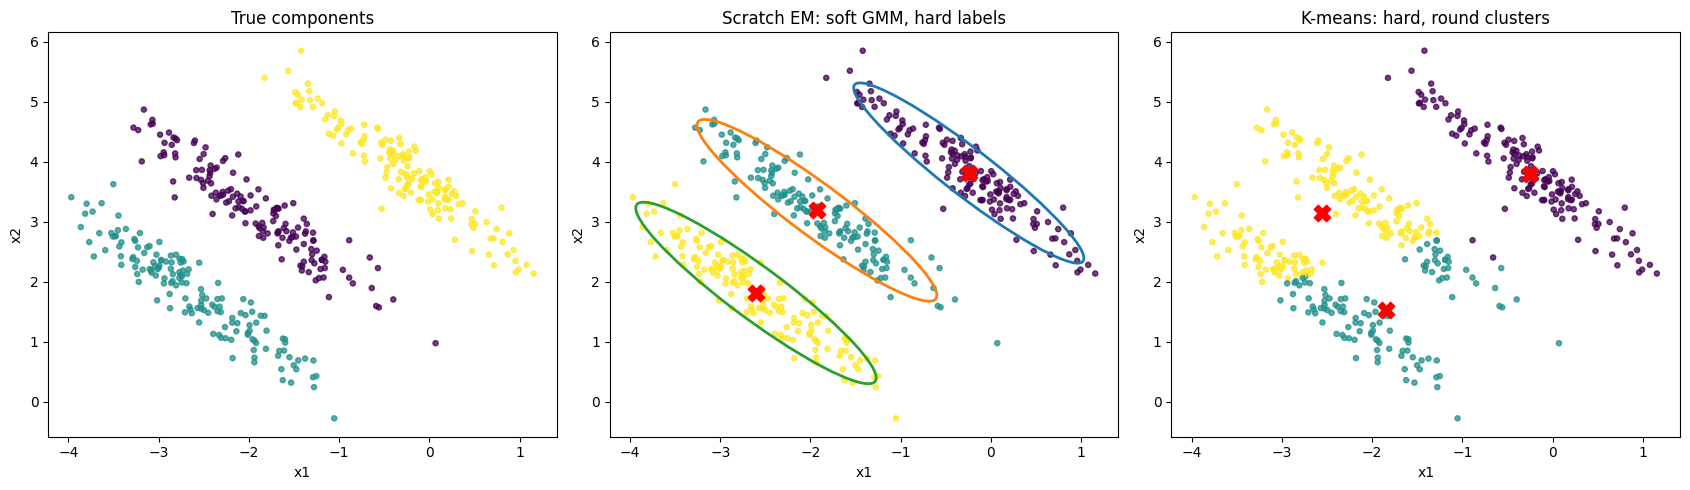

In [10]:
def draw_ellipse(ax, mean, covariance, color, n_std=2.0):
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = eigenvalues.argsort()[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]
    angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))
    width, height = 2 * n_std * np.sqrt(eigenvalues)
    ellipse = Ellipse(
        xy=mean,
        width=width,
        height=height,
        angle=angle,
        fill=False,
        color=color,
        linewidth=2,
    )
    ax.add_patch(ellipse)


colors = ["tab:blue", "tab:orange", "tab:green"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].scatter(X[:, 0], X[:, 1], c=y_true, cmap="viridis", s=14, alpha=0.75)
axes[0].set_title("True components")

axes[1].scatter(X[:, 0], X[:, 1], c=scratch_labels, cmap="viridis", s=14, alpha=0.75)
for k in range(3):
    draw_ellipse(axes[1], scratch_gmm["means"][k], scratch_gmm["covariances"][k], colors[k])
axes[1].scatter(
    scratch_gmm["means"][:, 0],
    scratch_gmm["means"][:, 1],
    c="red",
    marker="X",
    s=140,
)
axes[1].set_title("Scratch EM: soft GMM, hard labels")

axes[2].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap="viridis", s=14, alpha=0.75)
axes[2].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="red", marker="X", s=140)
axes[2].set_title("K-means: hard, round clusters")

for ax in axes:
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

plt.tight_layout()
plt.show()

The comparison is not "GMM always wins". If the clusters really are round and similarly sized,
k-means is simpler and faster. GMM is useful when clusters have different shapes, sizes, or
orientations, and when soft membership is meaningful.

## 8. Log-likelihood convergence

EM should not decrease the observed-data log-likelihood. Small numerical decreases can occur because
of the covariance ridge term or floating-point error, but the overall trend should be upward.

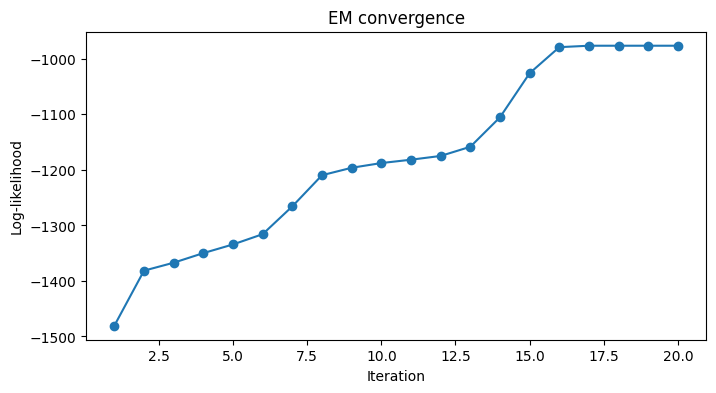

First log-likelihood: -1480.65
Final log-likelihood: -976.423
Total improvement: 504.228


In [11]:
history = scratch_gmm["log_likelihood_history"]

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(history) + 1), history, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("EM convergence")
plt.show()

print("First log-likelihood:", round(history[0], 3))
print("Final log-likelihood:", round(history[-1], 3))
print("Total improvement:", round(history[-1] - history[0], 3))

## 9. Choosing the number of components with BIC

More components always fit the training data at least as well, so likelihood alone cannot choose
$K$. The Bayesian information criterion penalises complexity:

$$
\mathrm{BIC} = -2\ell(\hat\theta) + p\log n,
$$

where $p$ is the number of free parameters. Lower BIC is better. AIC uses a weaker penalty
($2p$ instead of $p\log n$).

In [12]:
model_selection_rows = []

for K in range(1, 8):
    model = GaussianMixture(
        n_components=K,
        covariance_type="full",
        n_init=5,
        random_state=RANDOM_STATE,
    ).fit(X)
    model_selection_rows.append(
        {
            "n_components": K,
            "bic": model.bic(X),
            "aic": model.aic(X),
            "log_likelihood": model.score(X) * len(X),
        }
    )

model_selection = pd.DataFrame(model_selection_rows).set_index("n_components")
model_selection.round(3)

,bic,aic,log_likelihood
n_components,,,
1,2826.683,2806.136,-1398.068
2,2437.230,2392.028,-1185.014
3,2056.702,1986.845,-976.423
4,2087.724,1993.212,-973.606
5,2116.926,1997.758,-969.879
6,2135.116,1991.293,-960.646
7,2169.388,2000.909,-959.454


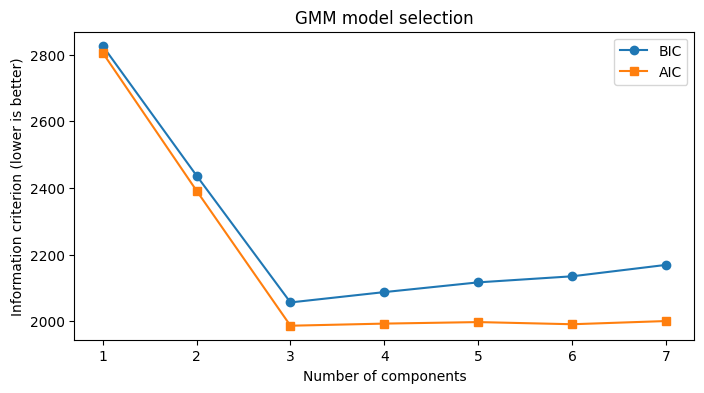

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(model_selection.index, model_selection["bic"], marker="o", label="BIC")
plt.plot(model_selection.index, model_selection["aic"], marker="s", label="AIC")
plt.xlabel("Number of components")
plt.ylabel("Information criterion (lower is better)")
plt.title("GMM model selection")
plt.legend()
plt.show()

BIC often selects a smaller model than AIC. Neither criterion knows the true $K$; they are
approximations. Always combine them with domain knowledge and out-of-sample or downstream
evaluation.

## 10. Cautions

- **Local optima.** EM converges to a local optimum. Use multiple initialisations (`n_init`) and
  compare final likelihoods.
- **Initialisation.** K-means or k-means++ is a common starting point for GMM parameters.
- **Singular covariances.** A component can collapse onto one point; covariance regularisation
  helps, but degenerate solutions still require care.
- **Gaussian assumption.** Heavy tails or non-Gaussian cluster shapes may need a different mixture
  or a transformation.
- **Label switching.** Component numbers are not identified; compare partitions, not labels.
- **Soft labels are not truth.** Responsibilities are model-based probabilities, conditional on the
  fitted mixture and its assumptions.
- **Scalability.** Full covariance has $O(Kd^2)$ parameters; for high-dimensional data use diagonal
  or tied covariances, or reduce dimensionality first.

## Summary

- A GMM represents clusters as Gaussian components with weights, means, and covariances.
- EM alternates responsibility computation (E-step) and parameter updates (M-step).
- Responsibilities provide soft cluster memberships and reveal ambiguous points.
- Full-covariance GMMs can capture elongated, rotated clusters that k-means cannot.
- BIC/AIC help choose the number of components, but multiple restarts and validation are essential.

## Exercises

1. Fit a GMM with `covariance_type="spherical"` and compare its ARI with the full-covariance model.
2. Change the number of true clusters to four and see whether BIC recovers it.
3. Initialise EM with k-means centres and compare the number of iterations to random initialisation.
4. Plot the responsibility of one component as a heat map over a grid of points.
5. Create a cluster with 20 points and another with 500. How do the mixing weights reflect the
   imbalance?
6. Explain why the observed-data log-likelihood can be difficult to optimise directly.